In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import make_blobs
from sklearn.inspection import DecisionBoundaryDisplay

In [54]:
def generate_data(num_samples, scale, cat0_center, cat1_center, seed=42):
    np.random.seed(seed)
    n_cat0 = np.random.randint(num_samples // 10, num_samples * 9 // 10)
    n_cat1 = num_samples - n_cat0

    cat0_xpoints = np.random.normal(loc=cat0_center[0], scale=scale, size=(n_cat0, 1))
    cat0_ypoints = np.random.normal(loc=cat0_center[1], scale=scale, size=(n_cat0, 1))
    cat0_points = np.hstack((cat0_xpoints, cat0_ypoints))
    cat0_labels = np.zeros(n_cat0)
    
    cat1_xpoints = np.random.normal(loc=cat1_center[0], scale=scale, size=(n_cat1, 1))
    cat1_ypoints = np.random.normal(loc=cat1_center[1], scale=scale, size=(n_cat1, 1))
    cat1_points = np.hstack((cat1_xpoints, cat1_ypoints))
    cat1_labels = np.ones(n_cat1)
    
    x = np.vstack((cat0_points, cat1_points))
    y = np.concatenate((cat0_labels, cat1_labels))
    
    indices = np.arange(num_samples)
    np.random.shuffle(indices)
    x = x[indices]
    y = y[indices].astype(int)
    return x, y
np.random.seed(42)
xpoints = np.random.normal(loc=50, scale=7, size=500)
ypoints = np.random.normal(loc=20, scale=7, size=500)
labels = ((xpoints > 40) & (xpoints < 60) & (ypoints > 15) & (ypoints < 25)).astype(int)

#x_train, y_train = generate_data(num_samples=500, scale=7.0, cat0_center=[50, 18], cat1_center=[70, 20], seed=42)

data = {'Miles_Per_week': xpoints,
        'Farthest_run': ypoints,
        'Qualified_Boston_Marathon': labels}

df= pd.DataFrame(data)
df

,Miles_Per_week,Farthest_run,Qualified_Boston_Marathon
0,53.476999,26.483243,0
1,49.032150,33.365916,0
2,54.533820,10.210027,0
3,60.661209,23.940785,0
4,48.360926,15.445502,1
...,...,...,...
495,53.772370,18.032298,1
496,42.739277,32.583806,0
497,48.667629,24.485900,1
498,43.870672,16.001747,1


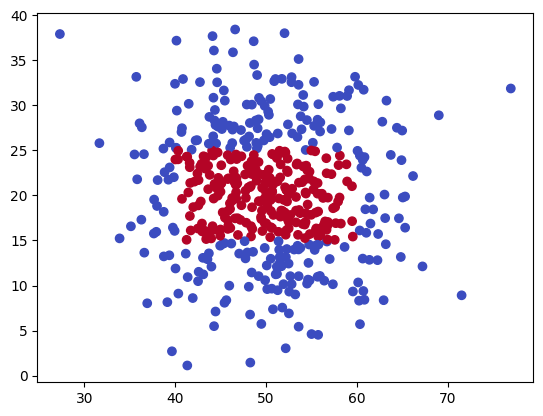

In [55]:
plt.scatter(x=df['Miles_Per_week'], y=df['Farthest_run'], c=df['Qualified_Boston_Marathon'], cmap='coolwarm')
#plt.xlabel('Miles_Per_week')
#plt.ylabel('Farthest_run')
#plt.colorbar(label='Qualified_Boston_Marathon')

In [56]:
x = df.iloc[:, 0:2]
x

,Miles_Per_week,Farthest_run
0,53.476999,26.483243
1,49.032150,33.365916
2,54.533820,10.210027
3,60.661209,23.940785
4,48.360926,15.445502
...,...,...
495,53.772370,18.032298
496,42.739277,32.583806
497,48.667629,24.485900
498,43.870672,16.001747


In [57]:
y = df.iloc[:, 2]
y

0      0
1      0
2      0
3      0
4      1
      ..
495    1
496    0
497    1
498    1
499    1
Name: Qualified_Boston_Marathon, Length: 500, dtype: int64

In [60]:
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=33, test_size=0.2)
model = SVC()
model.fit(x, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [61]:
model.score(x, y)

0.906

<Figure size 1000x600 with 0 Axes>

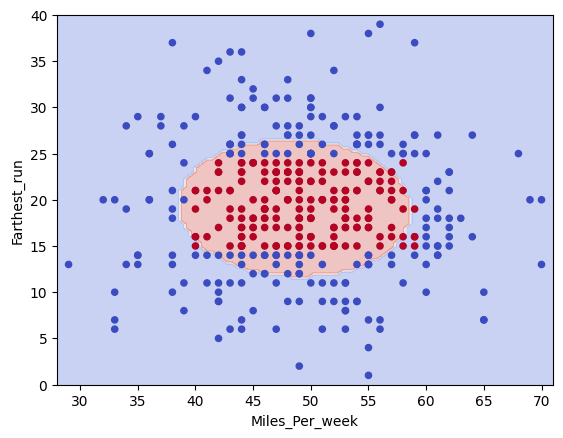

In [12]:
plt.figure(figsize=(10,6))
DecisionBoundaryDisplay.from_estimator(model, x_train, response_method="predict",cmap='coolwarm', alpha=0.3)
plt.scatter(x=x_train['Miles_Per_week'], y=x_train['Farthest_run'], c=y_train, cmap='coolwarm', s=20)

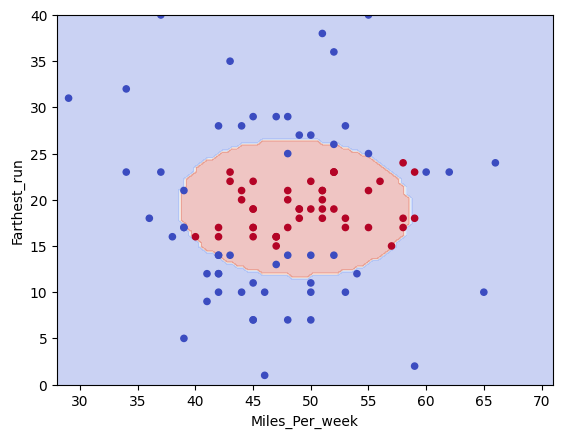

In [13]:
DecisionBoundaryDisplay.from_estimator(model, x_train, response_method="predict",cmap='coolwarm', alpha=0.3)
plt.scatter(x=x_test['Miles_Per_week'], y=x_test['Farthest_run'], c=y_test, cmap='coolwarm', s=20)

# Linear SVM to compare to py model

In [16]:
x, y = make_blobs(n_samples=100, centers=2, cluster_std=3.5, random_state=42)
y= y * 2. - 1
x.shape, y.shape, x[:5], y[:5]

((100, 2),
 (100,),
 array([[-4.18630746,  8.36447971],
        [ 8.43055819,  5.66147687],
        [-4.41453716,  9.40251519],
        [ 7.5170894 ,  8.61194512],
        [ 5.43598861,  6.54816932]]),
 array([-1.,  1., -1.,  1.,  1.]))

In [21]:
m = SVC(kernel='linear')
m.fit(x, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [22]:
m.score(x, y)

0.93

Text(0.5, 1.0, 'y_true')

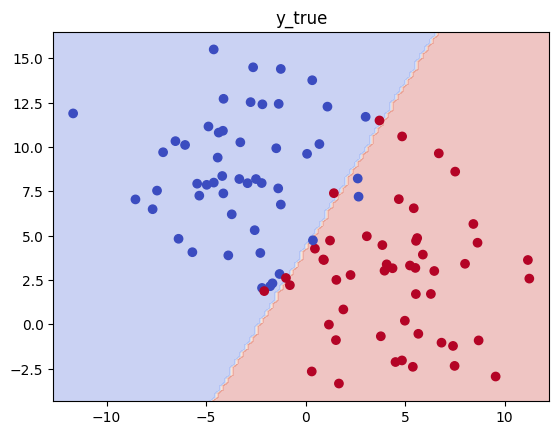

In [28]:
DecisionBoundaryDisplay.from_estimator(m, x, response_method="predict",cmap='coolwarm', alpha=0.3)
plt.scatter(x=x[:, 0], y=x[:, 1], c=y, cmap='coolwarm')
plt.title('y_true')

Text(0.5, 1.0, 'y_pred')

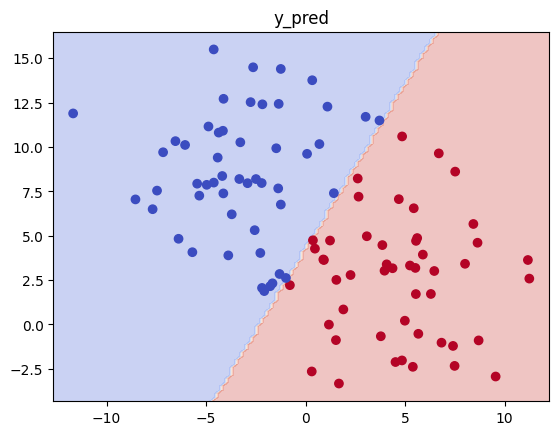

In [33]:
DecisionBoundaryDisplay.from_estimator(m, x, response_method="predict",cmap='coolwarm', alpha=0.3)
plt.scatter(x=x[:, 0], y=x[:, 1], c=m.predict(x), cmap='coolwarm')
plt.title('y_pred')

In [31]:
m.coef_, m.intercept_

(array([[ 1.01318465, -0.54702798]]), array([2.34224934]))

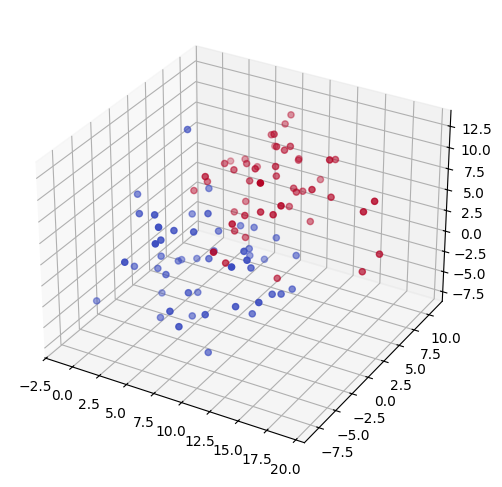

In [44]:
x, y = make_blobs(n_samples=100, centers=2, cluster_std=3.5, n_features=3, random_state=32)
x.shape, y.shape, x[:5], y[:5]
y= y * 2. - 1
fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={'projection': '3d'})
ax.scatter3D(x[:, 0], x[:, 1], x[:, 2], c=y, cmap='coolwarm')

In [45]:
m = SVC(kernel='linear')
m.fit(x, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [46]:
m.score(x, y)

0.89

In [47]:
m.coef_, m.intercept_

(array([[0.13805087, 0.3483349 , 0.31546203]]), array([-2.82165106]))